# 2 · REINFORCE: learning from your own games

**Notebook 2 of 4** — SFT → **REINFORCE** → PPO → AlphaZero-style MCTS.

Notebook 1 copied a teacher.  Now the network plays games itself and learns
from **one number per game: did it win?**  No teacher moves, no labels.

| | SFT (notebook 1) | REINFORCE (this notebook) |
|---|---|---|
| data | the teacher's games (fixed) | the learner's *own* games (fresh every iteration) |
| signal per move | the exact right move | the final result, shared by every move of the game |
| ceiling | the teacher | none in principle |
| main problem | distribution shift | **variance** of the gradient estimate |

We start from `checkpoints/sft.pt`, play batches of games against frozen
opponents, and nudge the policy towards the moves that were played in games it
won.  The output is `checkpoints/reinforce.pt` (the best evaluated iterate) and
`results/reinforce.json`.

**Runtime:** ~25–35 min on an M4 (most of it playing games).

In [1]:
import sys, json, time, copy, os
import multiprocessing as mp
from pathlib import Path
import numpy as np, chess, torch, torch.nn.functional as F
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "train" else Path.cwd().resolve()

def rel(p):
    """Path relative to the repo root (keeps absolute home paths out of outputs)."""
    p = Path(p).resolve()
    return str(p.relative_to(ROOT)) if ROOT in p.parents else str(p)
sys.path.insert(0, str(ROOT / "train"))
from chesslib.encoding import ACTION_SIZE, planes_to_float
from chesslib.model import (load_checkpoint, save_checkpoint, masked_log_softmax, wdl_to_scalar,
                            default_device, count_params)
from chesslib.rollouts import PolicySampler, play_rollouts, bot_move_fn, summarize
from chesslib.arena import play_match

DEVICE = default_device()
CKPT_DIR = ROOT / "train" / "checkpoints"; CKPT_DIR.mkdir(exist_ok=True)
RESULTS = ROOT / "train" / "results"; RESULTS.mkdir(exist_ok=True)
SFT_PATH = Path(os.environ.get("SFT_CKPT", CKPT_DIR / "sft.pt"))   # notebook 1's output
torch.manual_seed(0); np.random.seed(0)
print("device:", DEVICE, "| start from:", rel(SFT_PATH))

device: mps | start from: train/checkpoints/sft.pt


## 1 · The policy-gradient theorem in one screen

A game is a trajectory $\tau = (s_0, a_0, s_1, a_1, \dots)$; our moves are drawn
from $\pi_\theta(a\mid s)$, the opponent's moves and the rules are "the
environment".  The only reward is the final result $G(\tau) \in \{+1, 0, -1\}$
(win / draw / loss), so the objective is the expected score

$$J(\theta) = \mathbb E_{\tau\sim\pi_\theta}\,[G(\tau)].$$

We can't differentiate through the game, but we can differentiate the
*probability of the game*.  Using $\nabla p = p\,\nabla\log p$ (the
**score-function** or "log-derivative" trick) and the fact that only our own
move probabilities depend on $\theta$:

$$\nabla_\theta J = \mathbb E_\tau\Big[G(\tau)\,\nabla_\theta\log p_\theta(\tau)\Big]
 = \mathbb E_\tau\Big[\sum_t G(\tau)\,\nabla_\theta \log\pi_\theta(a_t\mid s_t)\Big].$$

That is an expectation we can **estimate by sampling**: play $N$ games, and for
every move we made take $G\cdot\nabla\log\pi(a_t\mid s_t)$.  As a loss to minimise:
$\mathcal L = -\tfrac1M\sum G\,\log\pi_\theta(a_t\mid s_t)$.  In words: *moves
from won games become more likely, moves from lost games less likely.*

### Baselines: same expectation, less noise

For any function $b(s)$ that does not depend on the action,

$$\mathbb E_{a\sim\pi}\big[b(s)\,\nabla\log\pi(a\mid s)\big] = b(s)\sum_a \nabla\pi(a\mid s) = b(s)\,\nabla\!\sum_a\pi(a\mid s) = b(s)\,\nabla 1 = 0,$$

so we may use the **advantage** $A_t = G - b(s_t)$ instead of $G$ without biasing
the gradient.  A good $b$ removes the part of $G$ that was predictable from the
position: if we were already winning ($b\approx+1$), winning again teaches
almost nothing; a draw from there ($A\approx-1$) is a real lesson.  The natural
choice is our own value head, $b(s)=V_\theta(s)$ — **detached**, so the policy
loss doesn't push the value around.

### Credit assignment
With one reward at the end, every move of a game gets *the same* $G$.  A
brilliant move in a lost game is punished; a blunder the opponent failed to
punish is rewarded.  Only averaging over many games separates them, which is
why REINFORCE needs a lot of games.  (γ = 1 here: in chess a move 40 plies
before mate matters as much as the last one.)

### Masked softmax — sample and learn from the *same* distribution
The network emits 4168 logits but only ~30 are legal.  We sample from the
softmax over legal moves, so the $\log\pi$ in the loss must be the **same
masked** log-softmax.  (Using an unmasked log-softmax in the loss silently
optimises a different distribution: most of its gradient goes into pushing
down illegal moves that were never playable.)

## 2 · Learner, reference and BatchNorm

* **learner** — trainable copy of the SFT network.
* **reference** — a frozen copy of SFT.  It is a training opponent, an
  evaluation opponent, and the anchor for an optional KL penalty.

**BatchNorm stays in eval mode for the whole notebook** (running statistics
frozen at their SFT values; the BN scale/shift parameters still train).  In
train mode BN normalises with the *current minibatch's* statistics, so the
network that computed $\log\pi$ during the update would not be the network
that sampled the moves — and RL minibatches (one opponent, one game phase,
correlated positions) have very different statistics from the SFT data.

In [2]:
learner = load_checkpoint(SFT_PATH, DEVICE).eval()
reference = load_checkpoint(SFT_PATH, DEVICE).eval()
for p in reference.parameters():
    p.requires_grad_(False)
print(f"{count_params(learner):,} parameters | SFT metadata: {getattr(learner, 'metadata', {})}")

564,331 parameters | SFT metadata: {'notebook': 'chess_sft', 'teacher': 'ab2', 'games': 6000, 'positions': 746155, 'val_top1': 0.4067265288773179}


## 3 · Who to play against?

A game is informative only if its result is *uncertain*: against an opponent
we beat 100% (or lose to 100%) of the time every game has the same $G$, the
baseline learns to predict it, and the advantage — the policy's learning
signal — is ≈ 0.

* **frozen SFT, sampling at T = 1** — by construction the learner starts at
  ~50%, the most informative score; it is also a *fixed* target, so (unlike
  pure self-play) a rising score means real improvement against something.
* **`ab1`** (alpha-beta, depth 1) — a stronger, *different* opponent: the
  evaluation target, and protection against over-fitting to SFT's quirks.

The cell below measures the starting score against each candidate with a small
probe, using the same rollout code as training.  The mix in `TRAIN_OPPONENTS`
(48 games vs frozen SFT + 16 vs `ab1` per iteration) follows from such numbers:
most games go where the result is genuinely uncertain (vs SFT).  The *sampling*
learner rarely scores against `ab1` (the argmax player in the evaluation below
does better — sampling at T = 1 plays a blunder every so often, and `ab1`
punishes every one), so those games are mostly losses with
advantage ≈ 0 — they teach the value head and reward the occasional
draw/win, but carry little policy signal, which is why they are only a quarter
of each batch.  `heuristic` is too weak to be informative as a training
opponent (the learner wins most games) but is a useful, sensitive
*evaluation* opponent.

In [3]:
ref_sampler = PolicySampler(reference, DEVICE, temperature=1.0)      # frozen opponent, sampling
OPPONENTS = {"sft": ref_sampler, "ab1": bot_move_fn("ab1", seed=1), "heuristic": bot_move_fn("heuristic", seed=1)}
learner_sampler = PolicySampler(learner, DEVICE, temperature=1.0)     # the learner samples at T = 1

t = time.time()
probe = {name: summarize(play_rollouts(learner_sampler, 32, fn, seed=1000 + i))
         for i, (name, fn) in enumerate(OPPONENTS.items())}
for name, s in probe.items():
    print(f"vs {name:9s}: score {s['score']:.0%}  (+{s['W']} ={s['D']} -{s['L']}), "
          f"{s['avg_plies']:.0f} plies, {s['terminations']}")
print(f"{time.time() - t:.0f}s")

vs sft      : score 50%  (+9 =14 -9), 125 plies, {'CHECKMATE': 18, 'THREEFOLD_REPETITION': 7, 'STALEMATE': 7}
vs ab1      : score 3%  (+1 =0 -31), 98 plies, {'CHECKMATE': 32}
vs heuristic: score 78%  (+19 =12 -1), 66 plies, {'THREEFOLD_REPETITION': 2, 'INSUFFICIENT_MATERIAL': 1, 'CHECKMATE': 20, 'STALEMATE': 9}
16s


All hyper-parameters in one place (each is explained where it is used):

In [4]:
# CONFIG — the knobs that matter
ITERS = 60                 # collect → update cycles
TRAIN_OPPONENTS = {"sft": 48, "ab1": 16}   # games per iteration against each opponent
LR = 1e-4                  # Adam learning rate
MINIBATCH = 1024           # positions per Adam step (≈ 4-6 steps per iteration)
VALUE_COEF = 0.5           # c_v
ENTROPY_COEF = 0.001       # c_H — small on purpose, see section 7
KL_COEF = 0.05             # β, KL(π_θ || π_SFT)
USE_BASELINE = True
MAX_GRAD_NORM = 1.0
EVAL_EVERY = 10            # iterations between evaluations
EVAL_GAMES = 60            # per evaluation opponent (paired random openings)
EVAL_SEED = 7              # same openings at every evaluation (and in notebook 3)
FINAL_GAMES, FINAL_SEED = 100, 99   # unbiased re-check of the selected iterate
WORKERS = 4
WARMUP_ROUNDS = 2           # critic warm-up batches (value head only, section 6)

## 4 · Turning games into a training batch

`play_rollouts` (in `chesslib/rollouts.py`) plays many games at once and keeps,
for every learner move: the board planes, the legal action indices, which one
was played and the result.  Here we flatten a list of games into arrays.  Every
position of a game gets the game's return $G$ from the side to move's view —
against a fixed opponent that is simply the learner's result.

In [5]:
def make_batch(trajs):
    trajs = [t for t in trajs if len(t.choice)]
    legal = [l.astype(np.int64) for t in trajs for l in t.legal]
    choice = [c for t in trajs for c in t.choice]
    mask = np.zeros((len(legal), ACTION_SIZE), bool)
    mask[np.repeat(np.arange(len(legal)), [len(l) for l in legal]), np.concatenate(legal)] = True
    G = np.concatenate([t.returns() for t in trajs]).astype(np.float32)
    return {"x": np.stack([p for t in trajs for p in t.planes]),            # (M, 21, 8, 8) uint8
            "mask": mask,                                                   # (M, 4168) legal moves
            "action": np.array([l[c] for l, c in zip(legal, choice)]),      # action index played
            "G": G,                                                         # return, side-to-move view
            "wdl": (1 - G).astype(np.int64),                                # +1/0/-1 -> class 0/1/2
            "logp_old": np.concatenate([t.logp for t in trajs]).astype(np.float32),
            "game": np.concatenate([np.full(len(t.choice), i) for i, t in enumerate(trajs)])}

def to_device(batch, idx):
    out = {k: torch.from_numpy(np.ascontiguousarray(v[idx])) for k, v in batch.items() if k != "x"}
    out["x"] = planes_to_float(batch["x"][idx])
    return {k: v.to(DEVICE) for k, v in out.items()}

def forward(model, mb):
    logits, wdl = model(mb["x"])
    logp_all = masked_log_softmax(logits, mb["mask"])                      # log π over LEGAL moves
    logp = logp_all.gather(1, mb["action"][:, None]).squeeze(1)            # log π(a_t | s_t)
    return logp_all, logp, wdl

def collect(it_seed, opponents):
    trajs, by_opp = [], {}
    for j, (name, n) in enumerate(opponents.items()):
        tr = play_rollouts(learner_sampler, n, OPPONENTS[name], seed=10_000 * it_seed + j)
        by_opp[name] = summarize(tr); trajs += tr
    return trajs, by_opp

var_trajs = play_rollouts(learner_sampler, 64, ref_sampler, seed=1)   # 64 games vs frozen SFT
var_batch = make_batch(var_trajs)
print(summarize(var_trajs))
print({k: (v.shape, v.dtype) for k, v in var_batch.items()})

{'games': 64, 'W': 20, 'D': 22, 'L': 22, 'score': 0.484375, 'avg_plies': 108.15625, 'terminations': {'CHECKMATE': 42, 'THREEFOLD_REPETITION': 11, 'STALEMATE': 10, 'INSUFFICIENT_MATERIAL': 1}}
{'x': ((3333, 21, 8, 8), dtype('uint8')), 'mask': ((3333, 4168), dtype('bool')), 'action': ((3333,), dtype('int64')), 'G': ((3333,), dtype('float32')), 'wdl': ((3333,), dtype('int64')), 'logp_old': ((3333,), dtype('float32')), 'game': ((3333,), dtype('int64'))}


## 5 · Seeing the variance problem

How noisy is the gradient from one game?  For each of the 64 games above we
compute the *single-game* policy-gradient estimate

$$g_i = \sum_{t\in\text{game } i} \big(G_i - b(s_t)\big)\,\nabla_\theta\log\pi_\theta(a_t\mid s_t)$$

with different baselines: none ($b=0$), a constant (mean result of the *other*
games — leave-one-out, so it doesn't depend on game $i$'s own moves) and the
value head.  All have the same expectation $\mu$ (the true gradient); they
differ only in their spread $\sigma^2 = \mathbb E\lVert g_i-\mu\rVert^2$.  A batch of
$k$ games averages $k$ of them, so its noise is $\sigma^2/k$.

Two numbers per baseline:

* $\sigma^2$ relative to no baseline — lower is better;
* the **noise share** of the 64-game batch gradient,
  $\frac{\sigma^2/64}{\lVert\bar g\rVert^2}$: the fraction of the squared length of
  the gradient we would actually step along that is noise.  ≈ 100% means the
  64 games do not even determine the *direction* of the true gradient.

In [6]:
def per_game_gradient_stats(model, batch, baselines=("none", "constant", "value head")):
    params = [p for n, p in model.named_parameters() if not n.startswith("value")]   # policy path only
    n_games = int(batch["game"].max()) + 1
    z = np.array([batch["G"][batch["game"] == i][0] for i in range(n_games)])
    stats = {k: {"sum": None, "sq": 0.0} for k in baselines}
    for i in range(n_games):
        mb = to_device(batch, np.nonzero(batch["game"] == i)[0])
        _, logp, wdl = forward(model, mb)
        b_all = {"none": torch.zeros_like(logp),
                 "constant": torch.full_like(logp, float(np.delete(z, i).mean())),
                 "value head": wdl_to_scalar(wdl).detach()}
        for name in baselines:
            loss = -((mb["G"] - b_all[name]) * logp).sum()
            g = torch.cat([x.flatten() for x in torch.autograd.grad(loss, params, retain_graph=True)])
            s = stats[name]
            s["sum"] = g if s["sum"] is None else s["sum"] + g
            s["sq"] += float((g * g).sum())
    out = {}
    for name, s in stats.items():
        mean2 = float((s["sum"] / n_games).pow(2).sum())             # ||ḡ||²
        var = s["sq"] / n_games - mean2                               # σ² = E||g - ḡ||²
        out[name] = {"sigma2": var, "mean2": mean2, "noise_share": min(var / n_games / mean2, 1.0)}
    return out

@torch.no_grad()
def value_loss_on(model, batch, chunk=1024):
    tot = 0.0
    for s in range(0, len(batch["G"]), chunk):
        mb = to_device(batch, np.arange(s, min(s + chunk, len(batch["G"]))))
        tot += F.cross_entropy(model(mb["x"])[1], mb["wdl"], reduction="sum").item()
    return tot / len(batch["G"])

t = time.time()
var_stats = per_game_gradient_stats(learner, var_batch)
var_stats["value head"]["value_loss"] = value_loss_on(learner, var_batch)
for name, s in var_stats.items():
    print(f"{name:12s}: σ² = {s['sigma2']:9.3g} ({s['sigma2'] / var_stats['none']['sigma2']:5.2f} × none)   "
          f"noise share of a 64-game gradient: {s['noise_share']:.0%}")
print(f"value head WDL loss on these games: {var_stats['value head']['value_loss']:.3f}   ({time.time() - t:.0f}s)")

none        : σ² =  4.59e+04 ( 1.00 × none)   noise share of a 64-game gradient: 94%
constant    : σ² =  4.77e+04 ( 1.04 × none)   noise share of a 64-game gradient: 94%
value head  : σ² =  4.23e+04 ( 0.92 × none)   noise share of a 64-game gradient: 69%
value head WDL loss on these games: 2.242   (6s)


Draws contribute **nothing** without a baseline ($G=0$), so that estimator
learns only from decisive games.  A baseline helps exactly as much as it
*predicts the result of these games*: the SFT value head was trained on the
teacher's games, not on games between two sampling networks (which end in far
more draws and blunders), so it may even make things worse — a confidently
wrong baseline adds noise.

## 6 · Warming up the critic

Standard practice before policy-gradient training: fit the **value head
alone** (policy and trunk frozen, so the policy is still exactly SFT) on a few
batches of games from the starting policy.  Then re-measure the variance on
the same 64 games as above (they were not used for the warm-up).

warm-up round 1: held-out value loss 1.241


warm-up round 2: held-out value loss 1.119


held-out value loss: SFT head 2.242 -> warmed up 1.119  (reference: uniform guess ln 3 = 1.099; best *constant* guess of these games' W/D/L frequencies = 1.073)   [25s]


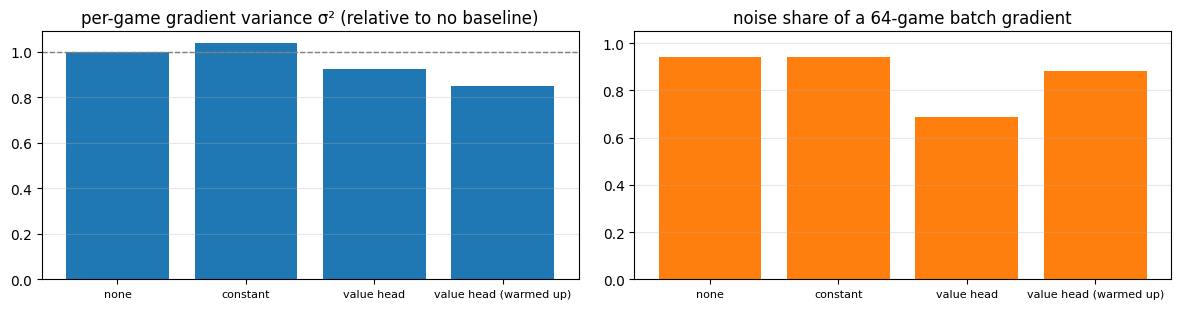

none                     σ² ratio  1.00   noise share  94%
constant                 σ² ratio  1.04   noise share  94%
value head               σ² ratio  0.92   noise share  69%
value head (warmed up)   σ² ratio  0.85   noise share  88%


In [7]:
def warmup_critic(model, rounds, epochs=3, lr=1e-3):
    head = [p for n, p in model.named_parameters() if n.startswith("value")]
    vopt = torch.optim.Adam(head, lr=lr)
    rng_w = np.random.default_rng(1)
    for r in range(rounds):
        b = make_batch(collect(900 + r, TRAIN_OPPONENTS)[0])
        for _ in range(epochs):
            perm = rng_w.permutation(len(b["G"]))
            for s in range(0, len(perm), 512):
                mb = to_device(b, perm[s:s + 512])
                loss = F.cross_entropy(model(mb["x"])[1], mb["wdl"])
                vopt.zero_grad(); loss.backward(); vopt.step()
        print(f"warm-up round {r + 1}: held-out value loss {value_loss_on(model, var_batch):.3f}")

t = time.time()
warmup_critic(learner, WARMUP_ROUNDS)
after = per_game_gradient_stats(learner, var_batch, baselines=("value head",))["value head"]
after["value_loss"] = value_loss_on(learner, var_batch)
var_stats["value head (warmed up)"] = after
freq = np.bincount(var_batch["wdl"], minlength=3) / len(var_batch["wdl"])
print(f"held-out value loss: SFT head {var_stats['value head']['value_loss']:.3f} -> warmed up {after['value_loss']:.3f}  "
      f"(reference: uniform guess ln 3 = {np.log(3):.3f}; best *constant* guess of these games' W/D/L "
      f"frequencies = {-(freq[freq > 0] * np.log(freq[freq > 0])).sum():.3f})   [{time.time() - t:.0f}s]")

names = list(var_stats)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
ax[0].bar(names, [var_stats[n]["sigma2"] / var_stats["none"]["sigma2"] for n in names], color="C0")
ax[0].axhline(1, color="gray", ls="--", lw=1); ax[0].set_title("per-game gradient variance σ² (relative to no baseline)")
ax[1].bar(names, [var_stats[n]["noise_share"] for n in names], color="C1"); ax[1].set_ylim(0, 1.05)
ax[1].set_title("noise share of a 64-game batch gradient")
for a in ax: a.tick_params(axis="x", labelsize=8); a.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()
for name, s in var_stats.items():
    print(f"{name:24s} σ² ratio {s['sigma2'] / var_stats['none']['sigma2']:5.2f}   noise share {s['noise_share']:4.0%}")

Read the bars like this: the left panel is the "baseline reduces variance"
claim measured directly — a baseline only helps when it predicts the result
of these games better than a constant does.  Check the printed value losses:
if the warmed-up head is barely better than the best constant guess, the
position simply doesn't tell the network much about how a game between two
*sampling* players will end (it is decided by blunders that haven't happened
yet), and the value baseline can't remove much variance.
The right panel is the sobering part: it shows how much of a 64-game gradient
is noise, i.e. how little one batch of games pins down the direction of the
true gradient.  That is the core weakness of REINFORCE: lots of games buy one
somewhat-reliable step.  The warmed-up value head is the baseline used from
here on (notebook 3 starts with the same warm-up).

## 7 · The REINFORCE loss

Per learner position $t$, with $\pi$ the masked softmax:

$$\mathcal L = \underbrace{-\big(G_t - \mathrm{sg}[V_\theta(s_t)]\big)\log\pi_\theta(a_t\mid s_t)}_{\text{policy gradient}}
\;+\; c_v\,\underbrace{\mathrm{CE}\big(\text{WDL}_\theta(s_t),\,G_t\big)}_{\text{value}}
\;-\; c_H\,\underbrace{H\big(\pi_\theta(\cdot\mid s_t)\big)}_{\text{entropy bonus}}
\;+\; \beta\,\underbrace{\mathrm{KL}\big(\pi_\theta\,\Vert\,\pi_{\text{SFT}}\big)}_{\text{stay near SFT}}$$

* $\mathrm{sg}[\cdot]$ = stop-gradient (detach).
* The **entropy bonus** keeps the policy from collapsing onto one move too
  early — exploration comes only from sampling, so a collapsed policy stops
  learning.  We keep it *tiny*: the SFT policy is far from collapsed, and when
  the policy gradient is mostly noise (section 5) the entropy term is the only
  *consistent* gradient — with $c_H = 0.01$ a tuning run of this notebook did
  little except make the policy steadily flatter.
* The **KL penalty** keeps the learner close to the SFT policy.  With noisy
  gradients it is easy to "learn" something that hurts in positions the batch
  didn't contain; the KL term is a cheap regulariser against that drift.
* Reward is the game result only (+1/0/−1).  No material shaping: shaped
  rewards are easy to farm (an earlier version of this notebook rewarded
  material and learned to grab a pawn and shuffle into repetition draws).

**One pass per batch.**  The textbook algorithm takes one gradient step per
batch of games.  We split the batch into a few minibatches and take one Adam
step on each, using every position exactly once.  Strictly, later minibatches
are then sampled from a slightly older policy; with a small learning rate the
difference is negligible — and correcting for exactly this mismatch is the
idea behind PPO.

In [8]:
opt = torch.optim.Adam([p for p in learner.parameters() if p.requires_grad], lr=LR)

def reinforce_update(batch, rng):
    M = len(batch["G"]); logs = []
    perm = rng.permutation(M)                        # every position used exactly once
    for s in range(0, M, MINIBATCH):
        mb = to_device(batch, perm[s:s + MINIBATCH])
        logp_all, logp, wdl = forward(learner, mb)
        baseline = wdl_to_scalar(wdl).detach() if USE_BASELINE else torch.zeros_like(logp)
        adv = mb["G"] - baseline
        policy_loss = -(adv * logp).mean()
        value_loss = F.cross_entropy(wdl, mb["wdl"])
        probs = logp_all.exp()
        entropy = -(probs * logp_all).sum(1).mean()
        with torch.no_grad():
            ref_logp_all = masked_log_softmax(reference(mb["x"])[0], mb["mask"])
        kl_ref = (probs * (logp_all - ref_logp_all)).sum(1).mean()
        loss = policy_loss + VALUE_COEF * value_loss - ENTROPY_COEF * entropy + KL_COEF * kl_ref
        opt.zero_grad(); loss.backward()
        gnorm = torch.nn.utils.clip_grad_norm_(learner.parameters(), MAX_GRAD_NORM)
        opt.step()
        logs.append({"policy_loss": policy_loss.item(), "value_loss": value_loss.item(),
                     "entropy": entropy.item(), "kl_ref": kl_ref.item(), "grad_norm": gnorm.item(),
                     "adv_std": adv.std().item()})
    return {k: float(np.mean([l[k] for l in logs])) for k in logs[0]}

## 8 · Evaluation protocol

Training scores are measured with a *sampling* learner against a *sampling*
opponent.  The question we actually care about is how well the **raw policy**
plays (argmax, no search), so every `EVAL_EVERY` iterations we save the
current weights to a temporary checkpoint and play `play_match` matches:

* vs **`ab1`**, vs the **frozen SFT policy** (argmax), and vs **`heuristic`**
  (a weaker bot, more sensitive when the score vs `ab1` is near 0),
* `EVAL_GAMES` games each, paired random openings (each opening played twice
  with colours swapped), `WORKERS` = 4 parallel processes,
* the **same openings at every evaluation** (fixed seed), so differences
  between evaluations come from the policy, not from the openings.

60 games give a standard error of roughly ±6 percentage points on a score near
50%, so differences smaller than ~10 points between two evaluations are noise.

In [9]:
EVAL_OPP = {"ab1": {"type": "bot", "name": "ab1"},
            "sft": {"type": "policy", "checkpoint": str(SFT_PATH), "label": "SFT"},
            "heuristic": {"type": "bot", "name": "heuristic"}}
POOL = mp.get_context("spawn").Pool(WORKERS)      # reused by every match
TMP_FILES = []

def evaluate(model, tag, opponents=EVAL_OPP, n_games=EVAL_GAMES, seed=EVAL_SEED):
    path = CKPT_DIR / f"tmp_reinforce_{tag}.pt"     # unique name: workers cache models by path
    save_checkpoint(path, model); TMP_FILES.append(path)
    me = {"type": "policy", "checkpoint": str(path), "label": f"REINFORCE@{tag}"}
    out = {}
    for name, spec in opponents.items():
        if name == "sft" and tag == "it0":
            out[name] = {"W": 0, "D": 0, "L": 0, "score": 0.5, "terminations": {}}  # SFT vs itself
            continue
        m = play_match(me, spec, n_games, workers=WORKERS, seed=seed, pool=POOL)
        out[name] = {"W": m.wins, "D": m.draws, "L": m.losses, "score": m.score, "terminations": m.terminations}
    return out

def eval_key(ev):            # model selection: mean score over the two required opponents
    return (ev["ab1"]["score"] + ev["sft"]["score"]) / 2

t = time.time()
evals = [{"iter": 0, "games": 0, **evaluate(learner, "it0")}]
print(f"SFT baseline evaluated in {time.time() - t:.0f}s")

REINFORCE@it0 vs ab1: +11 =8 -41 (score 25.0%, Elo diff -191 ± 107)


REINFORCE@it0 vs heuristic: +45 =15 -0 (score 87.5%, Elo diff +338 ± 157)
SFT baseline evaluated in 10s


## 9 · Training loop

collect games → make batch → one REINFORCE pass → log → (every few iterations)
evaluate and remember the best weights.  Besides losses we log what the games
*look like*: score per opponent, game length and **how games end** — a rising
share of repetition draws would be the first sign of a degenerate policy.

In [10]:
rng = np.random.default_rng(0)
history = []
best = {"key": eval_key(evals[0]), "iter": 0, "state": copy.deepcopy(learner.state_dict())}
games_played = 0
t0 = time.time()
for it in range(1, ITERS + 1):
    t = time.time()
    trajs, by_opp = collect(it, TRAIN_OPPONENTS)
    games_played += len(trajs)
    t_play = time.time() - t
    batch = make_batch(trajs)
    stats = reinforce_update(batch, rng)
    terms = summarize(trajs)["terminations"]
    rep = terms.get("THREEFOLD_REPETITION", 0) + terms.get("FIVEFOLD_REPETITION", 0)
    history.append({"iter": it, "games": games_played, "positions": len(batch["G"]), **stats,
                    "score": {k: v["score"] for k, v in by_opp.items()},
                    "avg_plies": float(np.mean([t.plies for t in trajs])),
                    "repetition_frac": rep / len(trajs), "terminations": terms})
    print(f"it {it:2d} | " + " ".join(f"{k} {v['score']:.0%}" for k, v in by_opp.items()) +
          f" | rep {rep / len(trajs):.0%} len {history[-1]['avg_plies']:.0f} | ent {stats['entropy']:.2f} "
          f"kl {stats['kl_ref']:.3f} vloss {stats['value_loss']:.3f} | {t_play:.0f}s play, {time.time() - t - t_play:.0f}s update")
    if it % EVAL_EVERY == 0 or it == ITERS:
        ev = {"iter": it, "games": games_played, **evaluate(learner, f"it{it}")}
        evals.append(ev)
        if eval_key(ev) > best["key"]:
            best = {"key": eval_key(ev), "iter": it, "state": copy.deepcopy(learner.state_dict())}
        print(f"   eval @ {it}: ab1 {ev['ab1']['score']:.0%}  sft {ev['sft']['score']:.0%}  "
              f"heuristic {ev['heuristic']['score']:.0%}  (best so far: iter {best['iter']})")
print(f"training took {(time.time() - t0) / 60:.1f} min")

it  1 | sft 41% ab1 6% | rep 23% len 114 | ent 1.70 kl 0.013 vloss 0.881 | 10s play, 1s update


it  2 | sft 44% ab1 6% | rep 11% len 122 | ent 1.53 kl 0.061 vloss 0.976 | 11s play, 1s update


it  3 | sft 39% ab1 0% | rep 14% len 105 | ent 1.56 kl 0.155 vloss 0.937 | 7s play, 1s update


it  4 | sft 47% ab1 0% | rep 22% len 116 | ent 1.42 kl 0.151 vloss 0.716 | 9s play, 1s update


it  5 | sft 44% ab1 6% | rep 16% len 105 | ent 1.45 kl 0.097 vloss 0.949 | 11s play, 2s update


it  6 | sft 52% ab1 0% | rep 12% len 106 | ent 1.58 kl 0.079 vloss 0.916 | 14s play, 2s update


... (68 outputs left out)

it 60 | sft 48% ab1 0% | rep 12% len 115 | ent 1.48 kl 0.110 vloss 0.892 | 10s play, 1s update


REINFORCE@it60 vs ab1: +6 =15 -39 (score 22.5%, Elo diff -215 ± 112)


REINFORCE@it60 vs SFT: +9 =40 -11 (score 48.3%, Elo diff -12 ± 90)


REINFORCE@it60 vs heuristic: +48 =12 -0 (score 90.0%, Elo diff +382 ± 187)
   eval @ 60: ab1 22%  sft 48%  heuristic 90%  (best so far: iter 40)
training took 13.7 min


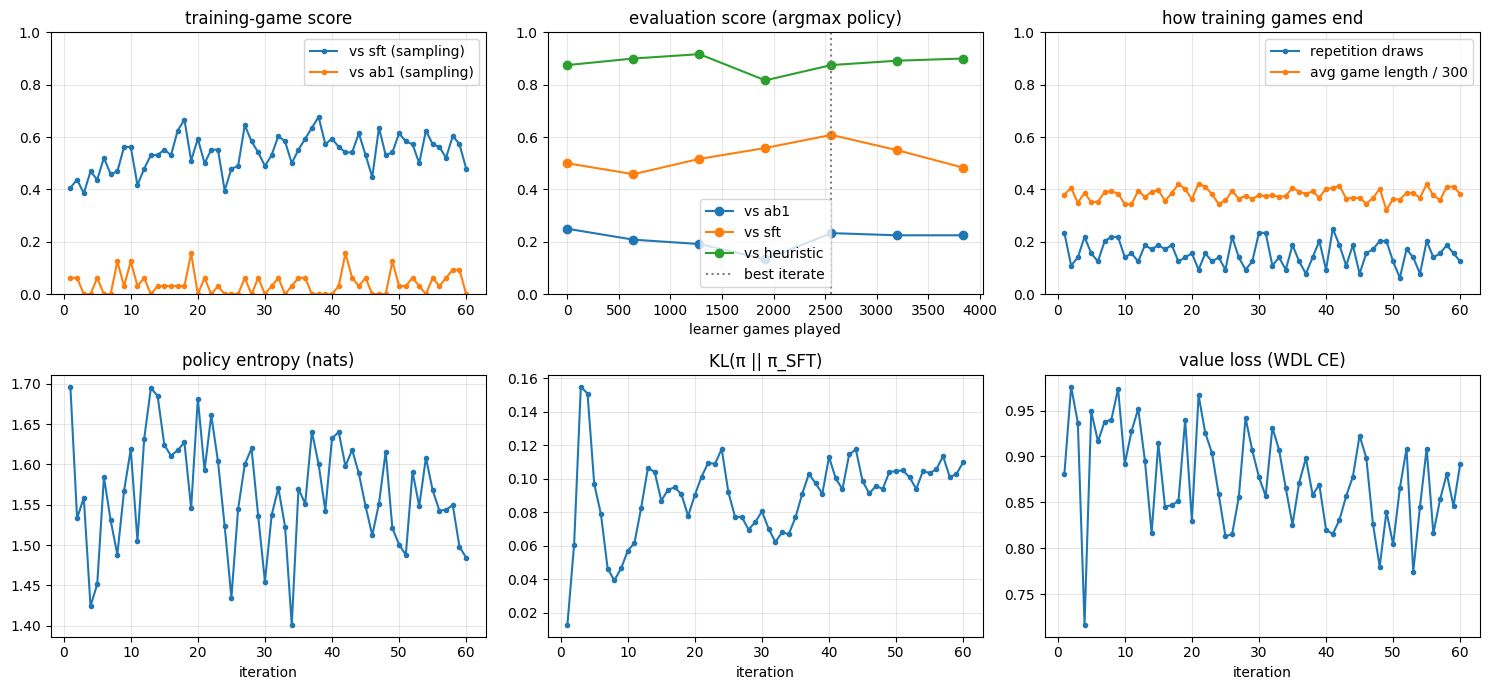

In [11]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
it_ = [h["iter"] for h in history]
for name in TRAIN_OPPONENTS:
    ax[0, 0].plot(it_, [h["score"][name] for h in history], ".-", label=f"vs {name} (sampling)")
ax[0, 0].set_title("training-game score"); ax[0, 0].set_ylim(0, 1); ax[0, 0].legend()
g = [e["games"] for e in evals]
for name in EVAL_OPP:
    ax[0, 1].plot(g, [e[name]["score"] for e in evals], "o-", label=f"vs {name}")
ax[0, 1].axvline(next(e["games"] for e in evals if e["iter"] == best["iter"]), color="gray", ls=":", label="best iterate")
ax[0, 1].set_title("evaluation score (argmax policy)"); ax[0, 1].set_xlabel("learner games played")
ax[0, 1].set_ylim(0, 1); ax[0, 1].legend()
ax[0, 2].plot(it_, [h["repetition_frac"] for h in history], ".-", label="repetition draws")
ax[0, 2].plot(it_, [h["avg_plies"] / 300 for h in history], ".-", label="avg game length / 300")
ax[0, 2].set_title("how training games end"); ax[0, 2].legend(); ax[0, 2].set_ylim(0, 1)
for a, key, title in [(ax[1, 0], "entropy", "policy entropy (nats)"), (ax[1, 1], "kl_ref", "KL(π || π_SFT)"),
                      (ax[1, 2], "value_loss", "value loss (WDL CE)")]:
    a.plot(it_, [h[key] for h in history], ".-"); a.set_title(title); a.set_xlabel("iteration")
for a in ax.flat: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 10 · Pick the best iterate and re-check it on fresh openings

The best iterate was chosen on the evaluation games, so its score there is
optimistically biased (we picked the luckiest of several noisy measurements).
To report an honest number we replay **both** the SFT starting point and the
selected iterate against the same opponents on *new* openings (different seed,
more games).

In [12]:
learner.load_state_dict(best["state"])
final_opp = {k: v for k, v in EVAL_OPP.items() if k != "sft"}
sft_model = load_checkpoint(SFT_PATH, "cpu")
final = {"sft": evaluate(sft_model, "final_sft", final_opp, FINAL_GAMES, FINAL_SEED),
         "reinforce": evaluate(learner, f"final_best{best['iter']}", EVAL_OPP, FINAL_GAMES, FINAL_SEED)}
final["sft"]["sft"] = {"score": 0.5}
save_checkpoint(CKPT_DIR / "reinforce.pt", learner, notebook="chess_reinforce", start=rel(SFT_PATH),
                best_iter=best["iter"], games_played=games_played)
print("saved", rel(CKPT_DIR / "reinforce.pt"), "(iteration", best["iter"], ")")

REINFORCE@final_sft vs ab1: +8 =18 -74 (score 17.0%, Elo diff -275 ± 96)


REINFORCE@final_sft vs heuristic: +77 =23 -0 (score 88.5%, Elo diff +354 ± 118)


REINFORCE@final_best40 vs ab1: +9 =25 -66 (score 21.5%, Elo diff -225 ± 86)


REINFORCE@final_best40 vs SFT: +18 =53 -29 (score 44.5%, Elo diff -38 ± 69)


REINFORCE@final_best40 vs heuristic: +82 =18 -0 (score 91.0%, Elo diff +402 ± 138)
saved train/checkpoints/reinforce.pt (iteration 40 )


In [13]:
result = {"config": {"iters": ITERS, "train_opponents": TRAIN_OPPONENTS, "lr": LR, "minibatch": MINIBATCH,
                     "value_coef": VALUE_COEF, "entropy_coef": ENTROPY_COEF, "kl_coef": KL_COEF,
                     "warmup_rounds": WARMUP_ROUNDS,
                     "eval_games": EVAL_GAMES, "eval_seed": EVAL_SEED, "start": rel(SFT_PATH)},
          "variance": var_stats, "probe": probe, "history": history, "evals": evals,
          "best_iter": best["iter"], "final": final}
(RESULTS / "reinforce.json").write_text(json.dumps(result, indent=2))
POOL.close(); POOL.join()
for p in TMP_FILES:
    p.unlink(missing_ok=True)

print(f"{'':12s}{'SFT':>8s}{'REINFORCE':>11s}   (fresh openings, {FINAL_GAMES} games each)")
for name in EVAL_OPP:
    a, b = final["sft"][name]["score"], final["reinforce"][name]["score"]
    print(f"vs {name:9s}{a:8.1%}{b:11.1%}   Δ = {100 * (b - a):+.1f} points")
s0, s1 = history[0], history[-1]
print(f"\ntraining games: repetition draws {s0['repetition_frac']:.0%} -> {s1['repetition_frac']:.0%}, "
      f"avg length {s0['avg_plies']:.0f} -> {s1['avg_plies']:.0f} plies, "
      f"entropy {s0['entropy']:.2f} -> {s1['entropy']:.2f}, KL to SFT {s1['kl_ref']:.3f}")
print("best iterate:", best["iter"], "of", ITERS, f"| {games_played} learner games in total")
k = min(5, len(history))
for name in TRAIN_OPPONENTS:
    a = np.mean([h["score"][name] for h in history[:k]]); b = np.mean([h["score"][name] for h in history[-k:]])
    print(f"training-game score vs {name} (both sides sampling): first {k} iterations {a:.0%} -> last {k} {b:.0%}")
def rep_share(ev):
    n = sum(ev["terminations"].values()) or 1
    return (ev["terminations"].get("THREEFOLD_REPETITION", 0) + ev["terminations"].get("FIVEFOLD_REPETITION", 0)) / n
print("final eval games ending in repetition: " + ", ".join(
    f"vs {n} {rep_share(final['sft'][n]):.0%} (SFT) -> {rep_share(final['reinforce'][n]):.0%}" for n in final_opp))

                 SFT  REINFORCE   (fresh openings, 100 games each)
vs ab1         17.0%      21.5%   Δ = +4.5 points
vs sft         50.0%      44.5%   Δ = -5.5 points
vs heuristic   88.5%      91.0%   Δ = +2.5 points

training games: repetition draws 23% -> 12%, avg length 114 -> 115 plies, entropy 1.70 -> 1.48, KL to SFT 0.110
best iterate: 40 of 60 | 3840 learner games in total
training-game score vs sft (both sides sampling): first 5 iterations 43% -> last 5 55%
training-game score vs ab1 (both sides sampling): first 5 iterations 4% -> last 5 6%
final eval games ending in repetition: vs ab1 13% (SFT) -> 18%, vs heuristic 5% (SFT) -> 7%


## 11 · Strengths and weaknesses

Read the table printed just above: the Δ column is the honest measure of what
REINFORCE achieved here (fresh openings, 100 games; a Δ within about ±10
points is not distinguishable from zero at this sample size).  The training
curves show whether the policy was still improving when we stopped, and the
termination stats show whether it got there by playing better chess or by
steering games into repetition draws.

Compare also the **training-game score** trend (printed above, both sides
sampling at T = 1) with the **argmax evaluation**.  They can disagree: policy
gradient reshapes the whole distribution — mostly it removes probability from
bad moves in the tail — while the argmax player only changes when the *top*
move changes.  A learner whose sampled play improved while its argmax play did
not has learned something real, just not something the evaluation measures.

**Strengths**
* **No teacher, no labels.** The signal is the game result alone, so in
  principle there is no ceiling — it can discover moves the teacher never
  played.
* **Learns where it plays.** Data comes from the learner's own positions, so
  it can fix exactly the mistakes it makes — the distribution-shift problem
  of SFT.
* **Simple and unbiased.** Twenty lines of loss code; with a baseline the
  estimator is still unbiased.

**Weaknesses (and why chess is hard for it)**
* **Variance.** One ±1 per game is shared by ~40–80 learner moves; sections 5–6
  show that most of a 64-game gradient is noise, and that the value baseline
  can't remove much of it when the value head can barely predict the
  outcome.  Most of the compute buys very little signal.
* **Credit assignment.** A loss after 60 moves usually comes from one or two
  bad moves; REINFORCE blames all 60 equally and relies on averaging over
  thousands of games to find the culprits.
* **Sample waste.** Each game is used for one gradient pass and thrown away
  (on-policy).
* **No lookahead.** The policy picks a move by "instinct" from one network
  call.  Tactics that need a few plies of calculation — exactly what `ab1`
  does with its search — must be memorised pattern by pattern.
* **Non-stationary target.** The value baseline is chasing a moving policy;
  the KL penalty and a small learning rate are what keep the updates from
  drifting.

**Next.** Notebook 3 (PPO) attacks the first three points: per-move advantages
from the value head (better credit assignment) and several epochs per batch
(sample reuse) made safe by a clipped importance ratio.  The last point — no
lookahead — is what notebook 4 (MCTS) is about: search turns the network's
instinct into calculated moves *and* produces a far richer training target
than a single game result.